# **5. Đánh giá mô hình**

So sánh baseline, mô hình lai và LightGBM bằng MAE, MSE, RMSE, R², R² hiệu chỉnh và RMSPE (chỉ số chính thức của cuộc thi). Mọi chỉ số tính trên doanh thu thật.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

FIG_DIR = Path('figures')  # [UPDATED] Thư mục lưu hình để chèn vào báo cáo
FIG_DIR.mkdir(exist_ok=True)


def save_fig(name):
    """[UPDATED] Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)


PROCESSED_DIR = Path('data/processed')
bundle = pd.read_pickle(PROCESSED_DIR / 'results.pkl')
results, n_features = bundle['results'], bundle['n_features']
MODELS = {'Baseline': 'pred_baseline', 'Hybrid': 'pred_hybrid', 'LightGBM': 'pred_lgbm'}

## 5.1 Bảng chỉ số đánh giá

In [2]:
def evaluate(actual, pred, n_feature):
    """[UPDATED] Gom việc tính các chỉ số vào một hàm (trước đây lặp lại code cho từng mô hình)."""
    n = len(actual)
    r2 = r2_score(actual, pred)
    return {
        'MAE': mean_absolute_error(actual, pred),
        'MSE': mean_squared_error(actual, pred),
        'RMSE': root_mean_squared_error(actual, pred),
        'R2': r2,
        'Adj_R2': 1 - (1 - r2) * (n - 1) / (n - n_feature - 1),
        'RMSPE': np.sqrt(np.mean(((actual - pred) / actual) ** 2)),  # [UPDATED] Chỉ số chính thức của cuộc thi Kaggle
    }


rows = [{'Split': split, 'Model': name, **evaluate(part['actual'], part[col], n_features[name])}
        for split, part in results.groupby('Split', sort=False) for name, col in MODELS.items()]
metrics = pd.DataFrame(rows)
metrics.to_csv(PROCESSED_DIR / 'metrics.csv', index=False)
print('Doanh thu trung bình tập test:', round(results.loc[results['Split'] == 'test', 'actual'].mean(), 1))
metrics.round({'MAE': 1, 'MSE': 0, 'RMSE': 1, 'R2': 4, 'Adj_R2': 4, 'RMSPE': 4})

Doanh thu trung bình tập test: 7205.9


,Split,Model,MAE,MSE,RMSE,R2,Adj_R2,RMSPE
0,train,Baseline,810.5,1558149.0,1248.3,0.8403,0.8403,0.2426
1,train,Hybrid,489.7,518051.0,719.8,0.9469,0.9469,0.1371
2,train,LightGBM,419.6,363458.0,602.9,0.9628,0.9628,0.1084
3,valid,Baseline,766.4,1343396.0,1159.0,0.8511,0.8511,0.1870
4,valid,Hybrid,709.4,1084872.0,1041.6,0.8797,0.8797,0.1744
5,valid,LightGBM,666.1,951202.0,975.3,0.8946,0.8945,0.1673
6,test,Baseline,805.3,1350641.0,1162.2,0.8567,0.8567,0.1559
7,test,Hybrid,656.2,844584.0,919.0,0.9104,0.9103,0.1256
8,test,LightGBM,632.5,786765.0,887.0,0.9165,0.9165,0.1217


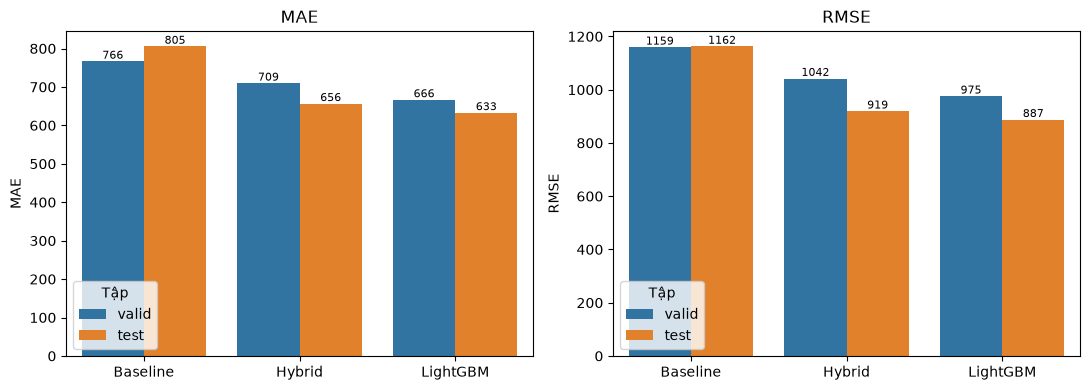

In [3]:
eval_metrics = metrics[metrics['Split'] != 'train']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    sns.barplot(data=eval_metrics, x='Model', y=metric, hue='Split', ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', fontsize=8)
    ax.set_title(metric)
    ax.set_xlabel('')
    ax.legend(title='Tập', loc='lower left')
save_fig('metrics_compare')

**Nhận xét:** trên tập kiểm tra, LightGBM tốt nhất (MAE 632,5; RMSE 887,0; R² 0,917), tiếp theo là Hybrid (MAE 656,2; R² 0,910). Cả hai đều tốt hơn rõ rệt so với Baseline (MAE 805,3; R² 0,857): LightGBM giảm MAE khoảng **21%**. MAE của LightGBM ≈ 8,8% doanh thu trung bình (7.206), RMSPE ≈ 12,2%. Sai số trên tập train thấp hơn tập kiểm tra (419,6 so với 632,5) — có quá khớp nhẹ nhưng kết quả trên dữ liệu mới vẫn tốt.

## 5.2 Phân tích phần dư

Phần dư = thực tế − dự đoán. Phần dư tập trung quanh 0 và cân đối nghĩa là mô hình không bị lệch về một phía.

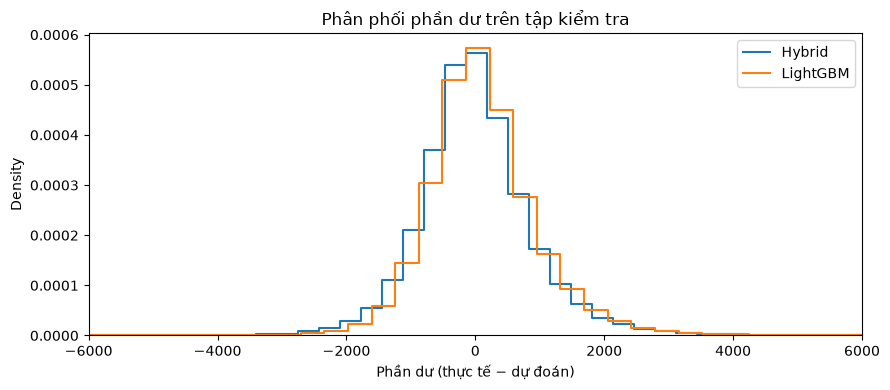

In [4]:
test_results = results[results['Split'] == 'test']
plt.figure(figsize=(9, 4))
for name in ['Hybrid', 'LightGBM']:
    sns.histplot(test_results['actual'] - test_results[MODELS[name]], bins=100, stat='density',
                 element='step', fill=False, label=name)
plt.xlim(-6000, 6000)
plt.xlabel('Phần dư (thực tế − dự đoán)')
plt.title('Phân phối phần dư trên tập kiểm tra')
plt.legend()
save_fig('residual_hist')

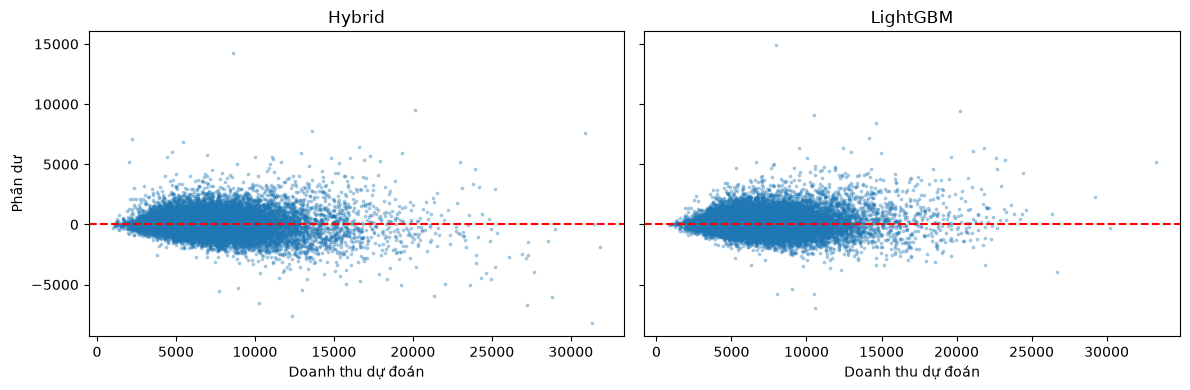

In [5]:
# [UPDATED] Vẽ phần dư theo giá trị dự đoán (sns.residplot cũ vẽ phần dư của một hồi quy phụ, không phải phần dư mô hình)
sample = test_results.sample(20_000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ['Hybrid', 'LightGBM']):
    ax.scatter(sample[MODELS[name]], sample['actual'] - sample[MODELS[name]], s=3, alpha=0.3)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_title(name)
    ax.set_xlabel('Doanh thu dự đoán')
axes[0].set_ylabel('Phần dư')
save_fig('residual_scatter')

In [6]:
# [UPDATED] Sai số theo mức doanh thu để xem mô hình yếu ở đâu
test_results = test_results.assign(SalesLevel=pd.qcut(test_results['actual'], 5, labels=['Rất thấp', 'Thấp', 'Trung bình', 'Cao', 'Rất cao']))
error_by_level = test_results.groupby('SalesLevel', observed=True).apply(
    lambda g: pd.Series({name: mean_absolute_error(g['actual'], g[col]) for name, col in MODELS.items()}))
error_by_level.round(0)

,Baseline,Hybrid,LightGBM
SalesLevel,,,
Rất thấp,476.0,421.0,404.0
Thấp,588.0,516.0,487.0
Trung bình,710.0,597.0,580.0
Cao,867.0,700.0,673.0
Rất cao,1386.0,1046.0,1018.0


**Nhận xét:** phần dư của hai mô hình có dạng chuông, tập trung quanh 0, LightGBM hơi hẹp hơn Hybrid. Sai số tăng theo mức doanh thu: nhóm doanh thu "Rất cao" có MAE khoảng 1.018 (LightGBM), gấp 2,5 lần nhóm "Rất thấp" (404) → mô hình yếu nhất ở những ngày doanh thu tăng đột biến.

## 5.3 So sánh thực tế và dự đoán theo thời gian

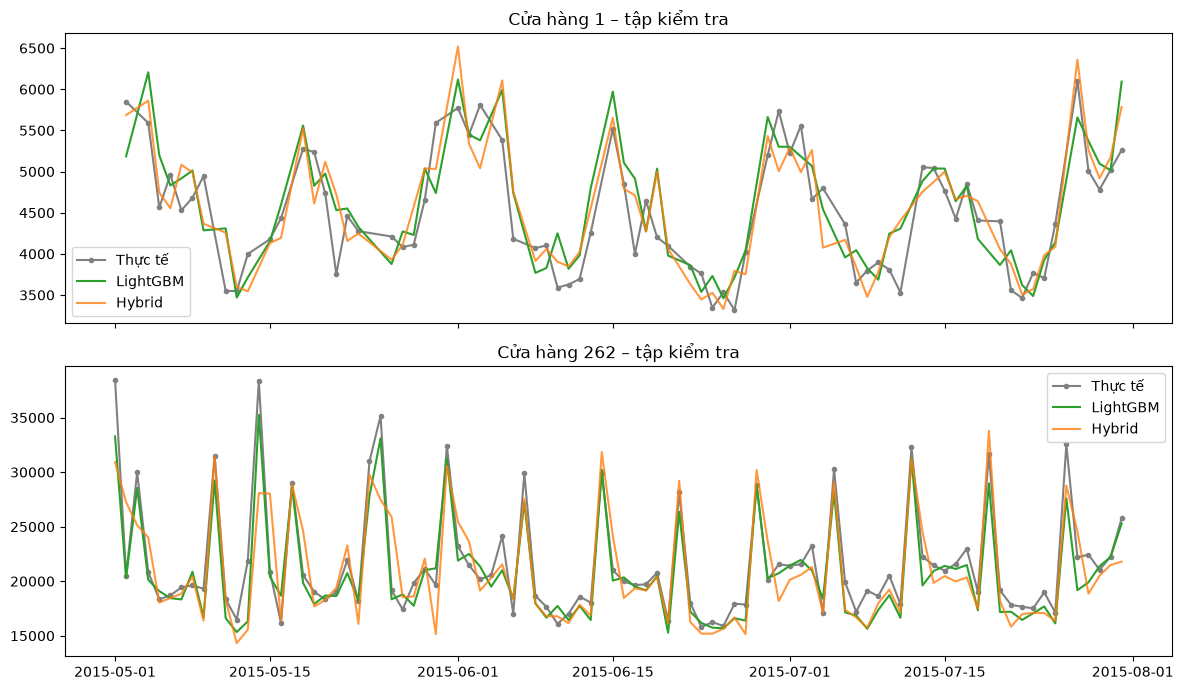

In [7]:
# [UPDATED] Vẽ theo thời gian cho từng cửa hàng (biểu đồ cũ nối 100 cửa hàng khác nhau trong cùng một ngày nên không có ý nghĩa)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, store_id in zip(axes, [1, 262]):
    store = test_results[test_results['Store'] == store_id]
    ax.plot(store['Date'], store['actual'], color='gray', marker='.', label='Thực tế')
    ax.plot(store['Date'], store['pred_lgbm'], color='tab:green', label='LightGBM')
    ax.plot(store['Date'], store['pred_hybrid'], color='tab:orange', alpha=0.8, label='Hybrid')
    ax.set_title(f'Cửa hàng {store_id} – tập kiểm tra')
    ax.legend()
save_fig('store_forecast')

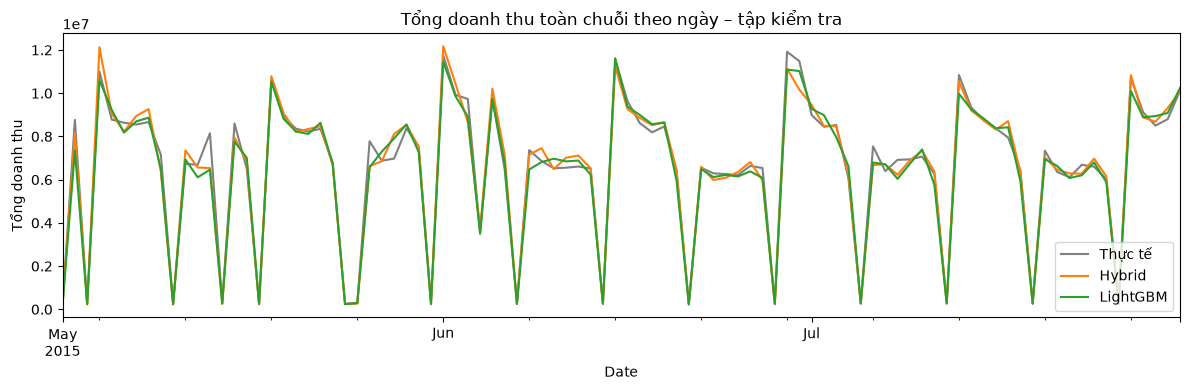

In [8]:
daily_total = test_results.groupby('Date')[['actual', 'pred_hybrid', 'pred_lgbm']].sum()
ax = daily_total.plot(figsize=(12, 4), color=['gray', 'tab:orange', 'tab:green'])
ax.legend(['Thực tế', 'Hybrid', 'LightGBM'])
ax.set_title('Tổng doanh thu toàn chuỗi theo ngày – tập kiểm tra')
ax.set_ylabel('Tổng doanh thu')
save_fig('daily_total')

## 5.4 Kết luận

- LightGBM là mô hình tốt nhất và ổn định nhất trên cả tập kiểm định lẫn tập kiểm tra; mô hình lai phức tạp hơn nhưng không tốt hơn.
- Hai mô hình học máy đều vượt baseline khoảng 18–21% theo MAE.
- Đặc trưng quan trọng nhất là doanh thu ngày bán trước (`lag_1`), thứ trong tuần và khuyến mãi — khớp với phân tích EDA.
- Hạn chế: do dùng `lag_1`, kết quả tương ứng với dự đoán **ngày kế tiếp**; muốn dự đoán xa hơn (6 tuần) cần dùng độ trễ dài hơn.